# Harris corner detector

About 15 minutes. Build the detector, check it on a white rectangle, then run it on the waterfront photo.


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tavisualcomputing/viscomp2026/blob/main/Exercises/W5/W5_harris_exercise.ipynb)

## Before you start

Run the setup cell first. It uses the photos next to this notebook, and downloads the ones it needs from the course repository when they are missing (this is what happens in Colab). If the download fails, upload the `.jpg` files from `Exercises/W5` into the Colab file browser.


In [41]:
%matplotlib inline
import matplotlib
import urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

plt.rcParams["figure.dpi"] = 80


IMAGE_BASE_URL = "https://raw.githubusercontent.com/tavisualcomputing/viscomp2026/main/Exercises/W5"


def find_image_dir():
    """Folder with the photos: next to the notebook, in images/, or in Exercises/W5."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        for folder in (cand, cand / "images", cand / "Exercises" / "W5"):
            if (folder / "line.jpg").is_file():
                return folder
    return start


IMAGE_DIR = find_image_dir()


def load_rgb(name):
    """Load a course photo. Downloads it on first use when it is not on disk."""
    path = IMAGE_DIR / name
    if not path.is_file():
        urllib.request.urlretrieve(f"{IMAGE_BASE_URL}/{name}", path)
    return np.asarray(Image.open(path).convert("RGB"))


def downscale(rgb, long_side=960):
    """Shrink so the long side is `long_side`. The JPEG on disk stays full HD."""
    image = Image.fromarray(rgb)
    image.thumbnail((long_side, long_side), Image.Resampling.LANCZOS)
    return np.asarray(image)


def rgb_to_gray(rgb):
    image = rgb.astype(np.float64)
    return (0.2989 * image[:, :, 0] + 0.5870 * image[:, :, 1] + 0.1140 * image[:, :, 2]) / 255.0


def image_gradients(gray):
    """Sobel derivatives. Ix is horizontal, Iy is vertical."""
    Ix = ndimage.sobel(gray, axis=1)
    Iy = ndimage.sobel(gray, axis=0)
    return Ix, Iy


## The detector

The structure tensor pools the image gradients in a Gaussian window:

$$
M = G_{\sigma} * \begin{bmatrix} I_x^2 & I_x I_y \\ I_x I_y & I_y^2 \end{bmatrix}
$$

Two large eigenvalues mean a corner. Harris skips the eigendecomposition:

$$
R = \det(M) - k\,(\mathrm{tr}\, M)^2
$$

Use $k = 0.05$. Corners give a large positive $R$. Straight edges give a negative $R$, because one eigenvalue is large and the other is near zero. Flat regions stay near zero.

`image_gradients` (already in the setup cell) returns Sobel derivatives $I_x$ and $I_y$.


## Your turn

Three short functions. The last one comes with a short guide. The check in the next section should print `Square check passed` before you run the photograph.


In [53]:
def structure_tensor(Ix, Iy, sigma):
    """Return A, B, C for M = [[A, C], [C, B]].

    Smooth Ix**2, Iy**2, and Ix*Iy with a Gaussian of standard deviation
    `sigma` (`ndimage.gaussian_filter`).
    """
    # ndimage.gaussian_filter(, sigma)
    A = ndimage.gaussian_filter(Ix**2, sigma)
    B = ndimage.gaussian_filter(Iy**2, sigma)
    C = ndimage.gaussian_filter(Ix*Iy, sigma)

    return A, B, C


In [36]:
def harris_response(A, B, C, k=0.05):
    """R = det(M) - k * trace(M)**2, with M = [[A, C], [C, B]]."""
    det_M = A * B - C**2
    trace_M = A + B
    return det_M - k * trace_M**2


## Two tools for picking corners

The last function needs two NumPy / SciPy tools you may not have used. Read this, run the demo cell, then write the function.

### 1. `ndimage.maximum_filter(array, size=n)` (given, you do not write it)

It slides an $n \times n$ window over the array. At every pixel it looks at the $n \times n$ neighbourhood centred on that pixel and writes the **largest value in that neighbourhood** into the output at the same position. The output has the same shape as the input.

Example with `size=3` (each output value is the max of the 3x3 block around it):

```
input            output
0 0 0 0 0        1 1 1 0 0
0 1 0 0 0        1 1 1 0 0
0 0 0 0 0   ->   1 1 5 5 5     the 1 spreads to its 8 neighbours,
0 0 0 5 0        0 0 5 5 5     the 5 spreads to its 8 neighbours
0 0 0 0 0        0 0 5 5 5
```

Why do we want this? A pixel is a **local maximum** exactly when nobody in its window is bigger than it, that is, when its own value equals the window maximum:

$$\text{response}[y, x] = \text{local\_max}[y, x]$$

Pixels that are only slightly less than a stronger neighbour fail this test. This is called **non-maximum suppression**: around each corner, the response forms a small hill, and we keep only the top of the hill instead of every pixel on it.

Warning: do not threshold `local_max` itself. It is the *spread-out* version, so every pixel near a strong corner would pass. Always compare against the original `response`.

### 2. `np.nonzero(mask)`

A comparison such as `response > 3` gives a boolean array with the same shape as `response`. `np.nonzero(mask)` turns this into a list of **where** the `True` entries are. For a 2-D array it returns two 1-D arrays, **first the row indices, then the column indices**:

```python
mask = np.array([[False, True,  False],
                 [False, False, True ],
                 [False, False, False]])
rows, cols = np.nonzero(mask)
# rows = [0, 1]    cols = [1, 2]     -> True at (row 0, col 1) and (row 1, col 2)
```

In an image rows are $y$ and columns are $x$, so write `ys, xs = np.nonzero(mask)`. Mixing these two up is the most common bug.

Boolean arrays can be combined element-wise with `&` (and). Put each comparison in its own parentheses: `(a == b) & (c > d)`.


In [35]:
# Demo: run this cell, change the numbers, and compare with the explanation.
demo = np.array([
    [0, 0, 0, 0, 0],
    [0, 1, 0, 0, 0],
    [0, 0, 0, 0, 0],
    [0, 0, 0, 5, 0],
    [0, 0, 0, 0, 0],
], dtype=float)

spread = ndimage.maximum_filter(demo, size=3)
print("maximum_filter, size=3:\n", spread)

is_peak = (demo == spread) & (demo > 0.5)
print("peaks (True where the pixel wins its window and is > 0.5):\n", is_peak)

rows, cols = np.nonzero(is_peak)
print("rows =", rows, " cols =", cols)


maximum_filter, size=3:
 [[1. 1. 1. 0. 0.]
 [1. 1. 1. 0. 0.]
 [1. 1. 5. 5. 5.]
 [0. 0. 5. 5. 5.]
 [0. 0. 5. 5. 5.]]
peaks (True where the pixel wins its window and is > 0.5):
 [[False False False False False]
 [False  True False False False]
 [False False False False False]
 [False False False  True False]
 [False False False False False]]
rows = [1 3]  cols = [1 3]


In [54]:

def select_corners(R, nms_size=9, rel_threshold=0.02):
    """Return xs, ys of the corner pixels.

    Keep a pixel when it is the maximum inside an `nms_size` window
    and its response is greater than `rel_threshold` times the
    strongest response in the image.
    Return no points if every response is <= 0.
    xs are columns, ys are rows.
    """
    response = R.copy()
    margin = nms_size // 2
    response[:margin, :] = 0   # clear a border so windows stay inside
    response[-margin:, :] = 0
    response[:, :margin] = 0
    response[:, -margin:] = 0

    # GIVEN: local_max[y, x] is the largest value of `response` in the
    # nms_size x nms_size window centred on (y, x). See the explanation above.
    local_max = ndimage.maximum_filter(response, size=nms_size)

    peak = float(response.max())
    # Your code here:
    # 1. If peak <= 0, return two empty integer arrays.
    # 2. Build a boolean array `mask` that is True where
    #    (a) response equals local_max         (the pixel wins its window)
    #    (b) response > rel_threshold * peak   (and it is strong enough)
    # 3. Turn the mask into coordinates with np.nonzero and return xs, ys.
    #    Careful: np.nonzero returns (rows, cols) = (ys, xs).

    if peak <= 0:
      return [], []
    mask = (response == local_max) & (response > rel_threshold * peak)
    rows, cols = np.nonzero(mask)
    return cols, rows


## Check: four corners of a rectangle

A white rectangle on a black background has a corner at each of its four corners and a long edge along each side. Those edges must not produce detections.


In [55]:
square = np.zeros((100, 120))
square[30:70, 20:90] = 1.0
Ix, Iy = image_gradients(square)
A, B, C = structure_tensor(Ix, Iy, sigma=1.5)
response = harris_response(A, B, C, k=0.05)
xs, ys = select_corners(response, nms_size=7, rel_threshold=0.1)

expected = {(20, 30), (89, 30), (20, 69), (89, 69)}
found = {(int(x), int(y)) for x, y in zip(xs, ys)}
print("Corners on the white rectangle:", sorted(found))
assert found == expected, "Expected the four corners of the rectangle."
print("Square check passed.")


Corners on the white rectangle: [(20, 30), (20, 69), (89, 30), (89, 69)]
Square check passed.


## Nyhavn

`images/line.jpg` is the waterfront. Windows are corners. Roof edges, masts, and the quay are lines. The drawing keeps the 250 strongest responses so the figure stays readable.


2903 corners above the threshold, drawing the strongest 250.


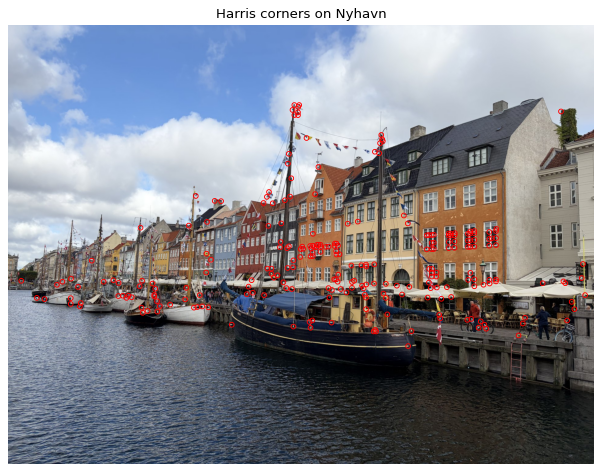

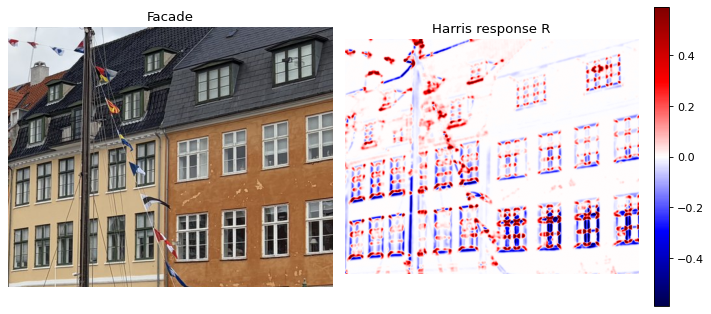

In [56]:
rgb = load_rgb("line.jpg")
gray = rgb_to_gray(rgb)
Ix, Iy = image_gradients(gray)
A, B, C = structure_tensor(Ix, Iy, sigma=1.6)
response = harris_response(A, B, C, k=0.05)
xs, ys = select_corners(response, nms_size=9, rel_threshold=0.02)

scores = response[ys, xs]
keep = np.argsort(scores)[-250:]
xs, ys = xs[keep], ys[keep]
print(f"{len(scores)} corners above the threshold, drawing the strongest {len(xs)}.")

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(rgb)
ax.scatter(xs, ys, s=18, facecolors="none", edgecolors="red", linewidths=0.8)
ax.set_title("Harris corners on Nyhavn")
ax.set_axis_off()
fig.tight_layout()
plt.show()

# A patch of facade. Red is a positive response, blue is a negative one.
y0, y1, x0, x1 = 380, 780, 1100, 1600
crop = response[y0:y1, x0:x1]
limit = np.percentile(np.abs(crop), 99)
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(rgb[y0:y1, x0:x1])
axes[0].set_title("Facade")
image = axes[1].imshow(crop, cmap="seismic", vmin=-limit, vmax=limit)
axes[1].set_title("Harris response R")
for ax in axes:
    ax.set_axis_off()
fig.colorbar(image, ax=axes[1], fraction=0.046)
fig.tight_layout()
plt.show()


## Look at the figures

1. Window corners are positive (red) in the response image, and the long vertical mast edges are negative (blue). Along a long edge one eigenvalue of $M$ is large and the other is near zero, so $\det(M)$ is near zero while $\mathrm{tr}(M)$ is large. The $k$ term then makes $R$ negative, and a negative value cannot be a local maximum we keep.
2. The marks in the first figure are those local maxima. Long straight stretches of the mast and the quay get no marks even though their gradient is strong. Marks appear only at the ends and junctions of such lines, where both eigenvalues are large.
